In [1]:
import math
import pandas as pd
pd.options.display.max_columns = None
import matplotlib.pyplot as plt
plt.show()
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
from statsmodels.stats.multitest import multipletests
import seaborn as sns
sns.set_style("white")
sns.set_style("ticks")
import numpy as np
from scipy import stats
import upsetplot as upset
import os
import matplotlib.patches as patches

In [5]:
# gene id - gene name correspondance
ensembl_ids_gene_name = pd.read_table('C:/Users/bacs5867/Documents/PABPN1/analyse/hg38_genome_ensembl_114/Homo_sapiens.GRCh38.114_ensembl_gene_names.txt', index_col=[0])

# load data from each analysis

In [6]:
# IR
nucleus_introns = pd.read_table('Fig3/IR_analysis_nuc.txt', index_col=[0], dtype={'chrom' : 'str'})
nucleus_introns.loc[nucleus_introns['sig'] == 'no', 'dir'] = 'not_significant'
nucleus_introns_sig = nucleus_introns[nucleus_introns['sig'] == 'yes']
nucleus_introns_more_IR = nucleus_introns[nucleus_introns['dir'] == 'more_IR_PABPN1']['gene_name'].drop_duplicates()
nucleus_introns_less_IR = nucleus_introns[nucleus_introns['dir'] == 'less_IR_PABPN1']['gene_name'].drop_duplicates()

cyto_introns = pd.read_table('Fig3/IR_analysis_cyto.txt', index_col=[0], dtype={'chrom' : 'str'})
cyto_introns.loc[cyto_introns['sig'] == 'no', 'dir'] = 'not_significant'
cyto_introns_sig = cyto_introns[cyto_introns['sig'] == 'yes']
cyto_introns_more_IR = cyto_introns[cyto_introns['dir'] == 'more_IR_PABPN1']['gene_name'].drop_duplicates()

# alternative polyA
apalord_res_nucleus = pd.read_table('Fig2/APA_gene_table_nucleus.txt')
apalord_res_nucleus = apalord_res_nucleus.dropna(subset = ['gene_name'])
apalord_res_nucleus_sig = apalord_res_nucleus[apalord_res_nucleus['APA_trend'] != 'no change']
apalord_shorter_nucleus = apalord_res_nucleus[apalord_res_nucleus['APA_trend'] == 'shorter']['gene_name'].drop_duplicates()
apalord_longer_nucleus = apalord_res_nucleus[apalord_res_nucleus['APA_trend'] == 'longer']['gene_name'].drop_duplicates()

apalord_res_cyto = pd.read_table('Fig2/APA_gene_table_cyto.txt')
apalord_res_cyto = apalord_res_cyto.dropna(subset = ['gene_name'])
apalord_res_cyto_sig = apalord_res_cyto[apalord_res_cyto['APA_trend'] != 'no change']
apalord_shorter_cyto = apalord_res_cyto[apalord_res_cyto['APA_trend'] == 'shorter']['gene_name'].drop_duplicates()
apalord_longer_cyto = apalord_res_cyto[apalord_res_cyto['APA_trend'] == 'longer']['gene_name'].drop_duplicates()

# differential expression
results_DESeq2_all = pd.read_table('Fig4/resDF_all.txt')
results_DESeq2_all = results_DESeq2_all[results_DESeq2_all['baseMean'] >= 10] # filter on basemean for sufficient coverage
results_DESeq2_all['localization_diff'] = 'No change'
results_DESeq2_all = results_DESeq2_all[results_DESeq2_all['gene_name'] != 'CA5BP1'] # remove CA5BP1, same gene symbols with 2 gene ids showing opposite patterns in expression
results_DESeq2_all.loc[(results_DESeq2_all['padj'] < 0.05) & (results_DESeq2_all['log2FoldChange'] >= 1), 'localization_diff'] = 'More cytoplasmic'
results_DESeq2_all.loc[(results_DESeq2_all['padj'] < 0.05) & (results_DESeq2_all['log2FoldChange'] <= -(1)), 'localization_diff'] = 'More nuclear'
results_DESeq2_all_sig = results_DESeq2_all[results_DESeq2_all['localization_diff'] != 'No change']
genes_more_nuclear = results_DESeq2_all[results_DESeq2_all['localization_diff'] == 'More nuclear']['gene_name'].drop_duplicates()
genes_more_cytoplasmic = results_DESeq2_all[results_DESeq2_all['localization_diff'] == 'More cytoplasmic']['gene_name'].drop_duplicates()

# m6A
cyto_genes_m6A = pd.read_table('Fig5/cyto_diff_m6A_merge_reps_cov_genes.txt', index_col=[0], dtype={'chrom' : 'str'})
cyto_genes_m6A = cyto_genes_m6A.merge(ensembl_ids_gene_name, on = 'Geneid', how = 'left')
cyto_genes_m6A.loc[cyto_genes_m6A['gene_name'].isna(), 'gene_name'] = cyto_genes_m6A['Geneid']
cyto_genes_m6A_more_methylated = cyto_genes_m6A[(cyto_genes_m6A['dir_x'] == 'more_modified') & (cyto_genes_m6A['dir_y'] == 'more_modified')]['gene_name'].drop_duplicates()

# keep genes covered in both long and short reads

In [ ]:
# long reads
dir_list_gene_counts = os.listdir('../snakemake_file/results/genes_reads_counts') # directory containing genes - read counts association
list_shCTL_cyto_df = []
list_shCTL_nucleus_df = []
list_shPABPN1_cyto_df = []
list_shPABPN1_nucleus_df = []

for file in dir_list_gene_counts :
    if 'shCTL_cyto' in file :
        list_shCTL_cyto_df.append(pd.read_table('../snakemake_file/results/genes_reads_counts/' + file, index_col=[0]))
    elif 'shCTL_noyau' in file :
        list_shCTL_nucleus_df.append(pd.read_table('../snakemake_file/results/genes_reads_counts/' + file, index_col=[0]))
    elif 'shPABPN1_cyto' in file :
        list_shPABPN1_cyto_df.append(pd.read_table('../snakemake_file/results/genes_reads_counts/' + file, index_col=[0]))
    elif 'shPABPN1_noyau' in file :
        list_shPABPN1_nucleus_df.append(pd.read_table('../snakemake_file/results/genes_reads_counts/' + file, index_col=[0]))

shCTL_cyto_read_counts = pd.concat(list_shCTL_cyto_df).reset_index(drop = True)
shCTL_cyto_read_counts = shCTL_cyto_read_counts.groupby(['chrom_gene', 'start_gene', 'end_gene', 'strand_gene', 'Geneid'])['read_id'].sum().reset_index()
shCTL_cyto_read_counts['condition'] = 'shCTL cytoplasm'

shCTL_nucleus_read_counts = pd.concat(list_shCTL_nucleus_df).reset_index(drop = True)
shCTL_nucleus_read_counts = shCTL_nucleus_read_counts.groupby(['chrom_gene', 'start_gene', 'end_gene', 'strand_gene', 'Geneid'])['read_id'].sum().reset_index()
shCTL_nucleus_read_counts['condition'] = 'shCTL nucleus'

shPABPN1_cyto_read_counts = pd.concat(list_shPABPN1_cyto_df).reset_index(drop = True)
shPABPN1_cyto_read_counts = shPABPN1_cyto_read_counts.groupby(['chrom_gene', 'start_gene', 'end_gene', 'strand_gene', 'Geneid'])['read_id'].sum().reset_index()
shPABPN1_cyto_read_counts['condition'] = 'shPABPN1 cytoplasm'

shPABPN1_nucleus_read_counts = pd.concat(list_shPABPN1_nucleus_df).reset_index(drop = True)
shPABPN1_nucleus_read_counts = shPABPN1_nucleus_read_counts.groupby(['chrom_gene', 'start_gene', 'end_gene', 'strand_gene', 'Geneid'])['read_id'].sum().reset_index()
shPABPN1_nucleus_read_counts['condition'] = 'shPABPN1 nucleus'

global_read_counts_nanopore = pd.concat([shCTL_cyto_read_counts, shCTL_nucleus_read_counts, shPABPN1_cyto_read_counts, shPABPN1_nucleus_read_counts]).reset_index(drop = True)
global_read_counts_nanopore = global_read_counts_nanopore.merge(ensembl_ids_gene_name, on = 'Geneid', how = 'left')
global_read_counts_nanopore.loc[global_read_counts_nanopore['gene_name'].isna(), 'gene_name'] = global_read_counts_nanopore['Geneid']

genes_cov_nanopore = global_read_counts_nanopore[global_read_counts_nanopore['read_id'] >= 20]['gene_name'].drop_duplicates().tolist() # keep genes covered by at least 20 reads


15122

In [ ]:
# short
genes_cov_short = results_DESeq2_all['gene_name'].drop_duplicates().tolist()

23444

In [10]:
# keep genes covered in both
genes_cov_both = []
for gene in genes_cov_nanopore :
    if (gene in genes_cov_short) and (gene not in genes_cov_both) :
        genes_cov_both.append(gene)

c:\Users\bacs5867\PycharmProjects\pythonProject\.venv\Lib\site-packages\upsetplot\plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
c:\Users\bacs5867\PycharmProjects\pythonProject\.venv\Lib\site-packages\upsetplot\plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on whi

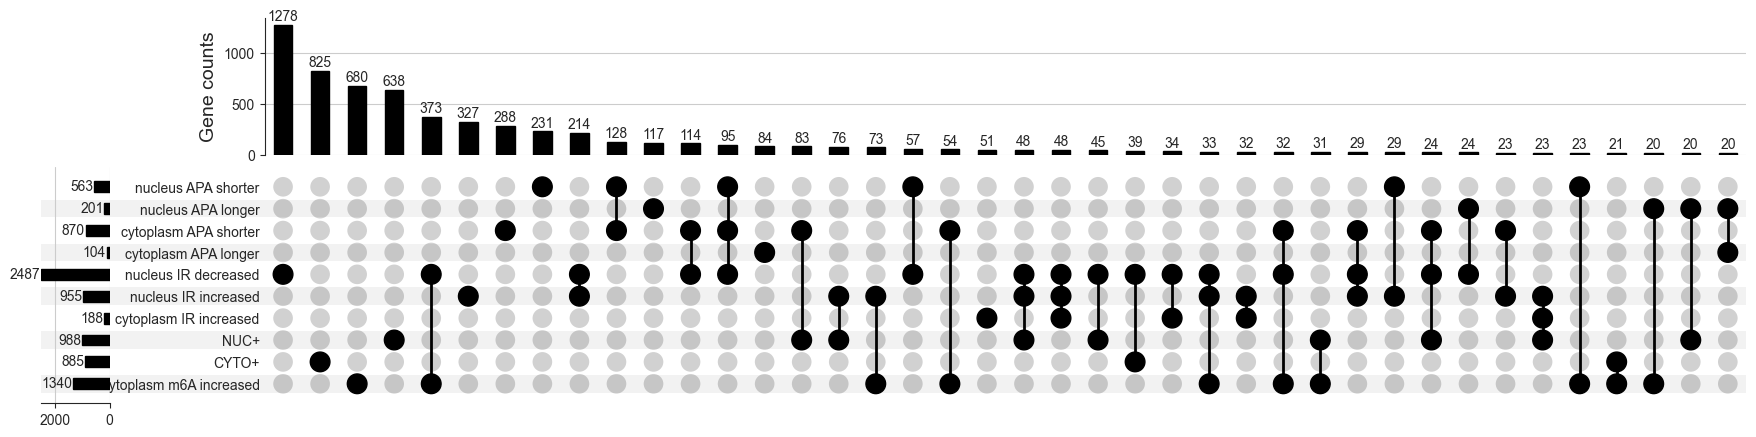

In [11]:
# upsetplot
df_upsetplot_all = pd.concat([nucleus_introns_sig['gene_name'], cyto_introns_sig['gene_name'], apalord_res_nucleus_sig['gene_name'], apalord_res_cyto_sig['gene_name'], results_DESeq2_all_sig['gene_name'], cyto_genes_m6A_more_methylated]).drop_duplicates().to_frame()
df_upsetplot_all['nucleus IR increased'] = False
df_upsetplot_all['nucleus IR decreased'] = False
df_upsetplot_all['cytoplasm IR increased'] = False
df_upsetplot_all['nucleus APA shorter'] = False
df_upsetplot_all['nucleus APA longer'] = False
df_upsetplot_all['cytoplasm APA shorter'] = False
df_upsetplot_all['cytoplasm APA longer'] = False
df_upsetplot_all['NUC+'] = False
df_upsetplot_all['CYTO+'] = False
df_upsetplot_all['cytoplasm m6A increased'] = False

df_upsetplot_all.loc[df_upsetplot_all['gene_name'].isin(nucleus_introns_more_IR.tolist()), 'nucleus IR increased'] = True
df_upsetplot_all.loc[df_upsetplot_all['gene_name'].isin(nucleus_introns_less_IR.tolist()), 'nucleus IR decreased'] = True
df_upsetplot_all.loc[df_upsetplot_all['gene_name'].isin(cyto_introns_more_IR.tolist()), 'cytoplasm IR increased'] = True
df_upsetplot_all.loc[df_upsetplot_all['gene_name'].isin(apalord_shorter_nucleus.tolist()), 'nucleus APA shorter'] = True
df_upsetplot_all.loc[df_upsetplot_all['gene_name'].isin(apalord_longer_nucleus.tolist()), 'nucleus APA longer'] = True
df_upsetplot_all.loc[df_upsetplot_all['gene_name'].isin(apalord_shorter_cyto.tolist()), 'cytoplasm APA shorter'] = True
df_upsetplot_all.loc[df_upsetplot_all['gene_name'].isin(apalord_longer_cyto.tolist()), 'cytoplasm APA longer'] = True
df_upsetplot_all.loc[df_upsetplot_all['gene_name'].isin(genes_more_nuclear.tolist()), 'NUC+'] = True
df_upsetplot_all.loc[df_upsetplot_all['gene_name'].isin(genes_more_cytoplasmic.tolist()), 'CYTO+'] = True
df_upsetplot_all.loc[df_upsetplot_all['gene_name'].isin(cyto_genes_m6A_more_methylated.tolist()), 'cytoplasm m6A increased'] = True

df_upsetplot_all_cov = df_upsetplot_all[df_upsetplot_all['gene_name'].isin(genes_cov_both)] # keep covered genes

df_upsetplot_all_count = df_upsetplot_all_cov.groupby(by = ['nucleus APA shorter', 'nucleus APA longer', 'cytoplasm APA shorter',
                                             'cytoplasm APA longer', 'nucleus IR decreased', 'nucleus IR increased', 'cytoplasm IR increased', 'NUC+', 'CYTO+', 'cytoplasm m6A increased'])['gene_name'].count()
df_upsetplot_all_count_high = df_upsetplot_all_count[df_upsetplot_all_count >= 20] # keep categories with more than 20 genes

# reorder
order = ['nucleus APA shorter', 'nucleus APA longer', 'cytoplasm APA shorter', 'cytoplasm APA longer', 'nucleus IR decreased', 'nucleus IR increased', 'cytoplasm IR increased', 'NUC+', 'CYTO+', 'cytoplasm m6A increased']
order.reverse()
df_upsetplot_all_count_high.index = df_upsetplot_all_count_high.index.reorder_levels(order)

fig = plt.figure(figsize=(22, 5))
upset.plot(df_upsetplot_all_count_high, show_counts=True, fig = fig, element_size=None, sort_by = 'cardinality', sort_categories_by='input')
plt.title('')
plt.ylabel('Gene counts', fontsize = 14)
plt.show()



# hypergeometric enrichment test

In [12]:
# create an effect column in each dataframe
nucleus_introns = nucleus_introns.rename(columns = {'dir' : 'effect'})
nucleus_introns['effect'] = nucleus_introns['effect'] + '_nucleus'

cyto_introns = cyto_introns.rename(columns = {'dir' : 'effect'})
cyto_introns['effect'] = cyto_introns['effect'] + '_cytoplasm'

apalord_res_nucleus = apalord_res_nucleus.rename(columns = {'APA_trend' : 'effect'})
apalord_res_nucleus['effect'] = apalord_res_nucleus['effect'] + '_nucleus'

apalord_res_cyto = apalord_res_cyto.rename(columns = {'APA_trend' : 'effect'})
apalord_res_cyto['effect'] = apalord_res_cyto['effect'] + '_cytoplasm'

results_DESeq2_all = results_DESeq2_all.rename(columns = {'localization_diff' : 'effect'})
results_DESeq2_all = results_DESeq2_all[results_DESeq2_all['gene_name'] != 'CA5BP1']

cyto_genes_m6A['effect'] = 'no_change'
cyto_genes_m6A.loc[(cyto_genes_m6A['dir_x'] == 'more_modified') & (cyto_genes_m6A['dir_y'] == 'more_modified'), 'effect'] = 'more_m6A'

In [13]:
# dictionnary that associates each effect to the corresponding dataframe
dict_effect_df = {'more_IR_PABPN1_nucleus' : nucleus_introns, 'less_IR_PABPN1_nucleus' : nucleus_introns, 'more_IR_PABPN1_cytoplasm' : cyto_introns,
                  'shorter_nucleus' : apalord_res_nucleus, 'longer_nucleus' : apalord_res_nucleus, 'shorter_cytoplasm' : apalord_res_cyto, 'longer_cytoplasm' : apalord_res_cyto,
                  'More nuclear' : results_DESeq2_all, 'More cytoplasmic' : results_DESeq2_all,
                  'more_m6A' : cyto_genes_m6A}

In [ ]:
# hypergeometric test for each comparison
list_effect1 = []
list_effect2 = []
list_N = []
list_n = []
list_K = []
list_k = []
list_pvalues = []
for effect1 in list(dict_effect_df.keys()) :
    for effect2 in list(dict_effect_df.keys()) :
        if effect1 != effect2 :
            df1 = dict_effect_df[effect1]
            df2 = dict_effect_df[effect2]
            df_merge = df1[['gene_name', 'effect']].drop_duplicates().merge(df2[['gene_name', 'effect']].drop_duplicates(), on = 'gene_name').drop_duplicates()
            N = len(df_merge['gene_name'].drop_duplicates().tolist())
            n = len(df_merge[df_merge['effect_x'] == effect1]['gene_name'].drop_duplicates().tolist())
            K = len(df_merge[df_merge['effect_y'] == effect2]['gene_name'].drop_duplicates().tolist())
            k = len(df_merge[(df_merge['effect_x'] == effect1) & (df_merge['effect_y'] == effect2)]['gene_name'].drop_duplicates().tolist())
            pvalue = stats.hypergeom.sf(k - 1, N, K, n)
            list_effect1.append(effect1)
            list_effect2.append(effect2)
            list_N.append(N)
            list_n.append(n)
            list_K.append(K)
            list_k.append(k)
            list_pvalues.append(pvalue)

hypergeom_df = pd.DataFrame(list_effect1)
hypergeom_df.columns = ['effect1']
hypergeom_df['effect2'] = list_effect2
hypergeom_df['N'] = list_N
hypergeom_df['n'] = list_n
hypergeom_df['K'] = list_K
hypergeom_df['k'] = list_k
hypergeom_df['pvalue'] = list_pvalues

hypergeom_df = hypergeom_df[~hypergeom_df[['effect1', 'effect2']].apply(lambda x: tuple(sorted(x)), axis=1).duplicated()] # keep only unique combinations of effects
hypergeom_df['FDR'] = multipletests(hypergeom_df['pvalue'].astype(float), alpha=0.05, method='fdr_bh')[1]

hypergeom_df['FC'] = (hypergeom_df['k'] / hypergeom_df['K']) / (hypergeom_df['n'] / hypergeom_df['N'])
hypergeom_df = hypergeom_df[hypergeom_df['FC'] != 0]
hypergeom_df['log2FC'] = hypergeom_df.apply(lambda row : math.log2(row.FC), axis = 1)

hypergeom_df['sig'] = 'no'
hypergeom_df.loc[(hypergeom_df['FDR'] < 0.05) & (abs(hypergeom_df['log2FC']) >= 0.5), 'sig'] = 'yes'

hypergeom_df

,effect1,effect2,N,n,K,k,pvalue,FDR,FC,log2FC,sig
0,more_IR_PABPN1_nucleus,less_IR_PABPN1_nucleus,8638,1310,2886,551,7.581517e-13,5.686138e-12,1.258917,0.332183,no
1,more_IR_PABPN1_nucleus,more_IR_PABPN1_cytoplasm,3349,804,356,192,1.831970e-38,2.747955e-37,2.246520,1.167692,yes
2,more_IR_PABPN1_nucleus,shorter_nucleus,6052,993,689,137,5.952764e-03,2.060572e-02,1.211856,0.277218,no
3,more_IR_PABPN1_nucleus,longer_nucleus,6052,993,263,56,2.017436e-02,5.663339e-02,1.297723,0.375982,no
4,more_IR_PABPN1_nucleus,shorter_cytoplasm,5370,859,983,179,2.139484e-02,5.663339e-02,1.138363,0.186960,no
5,more_IR_PABPN1_nucleus,longer_cytoplasm,5370,859,172,40,7.471756e-03,2.401636e-02,1.453827,0.539855,yes
6,more_IR_PABPN1_nucleus,More nuclear,8390,1275,654,253,1.392450e-53,3.133014e-52,2.545626,1.348020,yes
7,more_IR_PABPN1_nucleus,More cytoplasmic,8390,1275,256,32,9.073979e-01,1.000000e+00,0.822549,-0.281826,no
8,more_IR_PABPN1_nucleus,more_m6A,7807,1192,1440,200,9.518404e-01,1.000000e+00,0.909652,-0.136613,no
10,less_IR_PABPN1_nucleus,more_IR_PABPN1_cytoplasm,3349,1608,356,159,9.186057e-01,1.000000e+00,0.930200,-0.104388,no


In [26]:
# heatmap

# first df containing log2FC
hypergeom_df_heatmap = hypergeom_df[['effect1', 'effect2', 'log2FC']]
hypergeom_df_heatmap = pd.concat([hypergeom_df_heatmap, hypergeom_df_heatmap.rename(columns = {'effect1' : 'effect2', 'effect2' : 'effect1'})[['effect1', 'effect2', 'log2FC']]]).reset_index(drop = True)
hypergeom_df_heatmap_piv = hypergeom_df_heatmap.pivot_table(index = 'effect1', columns = 'effect2', values = 'log2FC')

order = ['shorter_nucleus', 'longer_nucleus', 'shorter_cytoplasm', 'longer_cytoplasm', 'less_IR_PABPN1_nucleus', 'more_IR_PABPN1_nucleus', 'more_IR_PABPN1_cytoplasm', 'More nuclear', 'More cytoplasmic', 'more_m6A']

hypergeom_df_heatmap_piv = hypergeom_df_heatmap_piv.reindex(order)
hypergeom_df_heatmap_piv = hypergeom_df_heatmap_piv[order]

new_names = ['nucleus APA shorter', 'nucleus APA longer', 'cytoplasm APA shorter', 'cytoplasm APA longer', 'nucleus IR decreased', 'nucleus IR increased', 'cytoplasm IR increased', 'NUC+', 'CYTO+', 'cytoplasm m6A\nincreased']

hypergeom_df_heatmap_piv.index = new_names
hypergeom_df_heatmap_piv.columns = new_names

hypergeom_df_heatmap_piv


,nucleus APA shorter,nucleus APA longer,cytoplasm APA shorter,cytoplasm APA longer,nucleus IR decreased,nucleus IR increased,cytoplasm IR increased,NUC+,CYTO+,cytoplasm m6A\nincreased
nucleus APA shorter,NaN,NaN,1.463837,-0.399744,0.256391,0.277218,0.279502,0.012888,0.256542,-0.298638
nucleus APA longer,NaN,NaN,0.272829,2.359269,-0.161523,0.375982,0.333305,1.089324,-0.120741,0.073327
cytoplasm APA shorter,1.463837,0.272829,NaN,NaN,0.254481,0.186960,0.316128,1.003282,-0.243636,-0.269283
cytoplasm APA longer,-0.399744,2.359269,NaN,NaN,-0.262837,0.539855,0.923184,-0.133312,0.123934,0.099450
nucleus IR decreased,0.256391,-0.161523,0.254481,-0.262837,NaN,0.332183,-0.104388,-0.042498,-0.372877,0.163924
nucleus IR increased,0.277218,0.375982,0.186960,0.539855,0.332183,NaN,1.167692,1.348020,-0.281826,-0.136613
cytoplasm IR increased,0.279502,0.333305,0.316128,0.923184,-0.104388,1.167692,NaN,0.950354,1.120703,-0.104598
NUC+,0.012888,1.089324,1.003282,-0.133312,-0.042498,1.348020,0.950354,NaN,NaN,-0.563187
CYTO+,0.256542,-0.120741,-0.243636,0.123934,-0.372877,-0.281826,1.120703,NaN,NaN,-0.598560
cytoplasm m6A\nincreased,-0.298638,0.073327,-0.269283,0.099450,0.163924,-0.136613,-0.104598,-0.563187,-0.598560,NaN


In [28]:
# second df with the FDR
hypergeom_df_pvalue = hypergeom_df[['effect1', 'effect2', 'FDR']]
hypergeom_df_pvalue = pd.concat([hypergeom_df_pvalue, hypergeom_df_pvalue.rename(columns = {'effect1' : 'effect2', 'effect2' : 'effect1'})[['effect1', 'effect2', 'FDR']]]).reset_index(drop = True)
hypergeom_df_pvalue_piv = hypergeom_df_pvalue.pivot_table(index = 'effect1', columns = 'effect2', values = 'FDR')

order = ['shorter_nucleus', 'longer_nucleus', 'shorter_cytoplasm', 'longer_cytoplasm', 'less_IR_PABPN1_nucleus', 'more_IR_PABPN1_nucleus', 'more_IR_PABPN1_cytoplasm', 'More nuclear', 'More cytoplasmic', 'more_m6A']

hypergeom_df_pvalue_piv = hypergeom_df_pvalue_piv.reindex(order)
hypergeom_df_pvalue_piv = hypergeom_df_pvalue_piv[order]

new_names = ['nucleus APA shorter', 'nucleus APA longer', 'cytoplasm APA shorter', 'cytoplasm APA longer', 'nucleus IR decreased', 'nucleus IR increased', 'cytoplasm IR increased', 'NUC+', 'CYTO+', 'cytoplasm m6A\nincreased']

hypergeom_df_pvalue_piv.index = new_names
hypergeom_df_pvalue_piv.columns = new_names

hypergeom_df_pvalue_piv

,nucleus APA shorter,nucleus APA longer,cytoplasm APA shorter,cytoplasm APA longer,nucleus IR decreased,nucleus IR increased,cytoplasm IR increased,NUC+,CYTO+,cytoplasm m6A\nincreased
nucleus APA shorter,NaN,NaN,3.444464e-98,1.000000e+00,3.132893e-04,2.060572e-02,3.504292e-01,8.710863e-01,0.350429,1.000000
nucleus APA longer,NaN,NaN,1.362634e-01,6.249305e-22,1.000000e+00,5.663339e-02,5.438540e-01,2.422970e-08,1.000000,0.660858
cytoplasm APA shorter,3.444464e-98,1.362634e-01,NaN,NaN,3.687447e-06,5.663339e-02,1.662347e-01,4.861712e-28,1.000000,1.000000
cytoplasm APA longer,1.000000e+00,6.249305e-22,NaN,NaN,1.000000e+00,2.401636e-02,2.936415e-02,1.000000e+00,0.871086,0.660858
nucleus IR decreased,3.132893e-04,1.000000e+00,3.687447e-06,1.000000e+00,NaN,5.686138e-12,1.000000e+00,1.000000e+00,1.000000,0.000506
nucleus IR increased,2.060572e-02,5.663339e-02,5.663339e-02,2.401636e-02,5.686138e-12,NaN,2.747955e-37,3.133014e-52,1.000000,1.000000
cytoplasm IR increased,3.504292e-01,5.438540e-01,1.662347e-01,2.936415e-02,1.000000e+00,2.747955e-37,NaN,4.965905e-07,0.001466,1.000000
NUC+,8.710863e-01,2.422970e-08,4.861712e-28,1.000000e+00,1.000000e+00,3.133014e-52,4.965905e-07,NaN,NaN,1.000000
CYTO+,3.504292e-01,1.000000e+00,1.000000e+00,8.710863e-01,1.000000e+00,1.000000e+00,1.466272e-03,NaN,NaN,1.000000
cytoplasm m6A\nincreased,1.000000e+00,6.608578e-01,1.000000e+00,6.608578e-01,5.064330e-04,1.000000e+00,1.000000e+00,1.000000e+00,1.000000,NaN


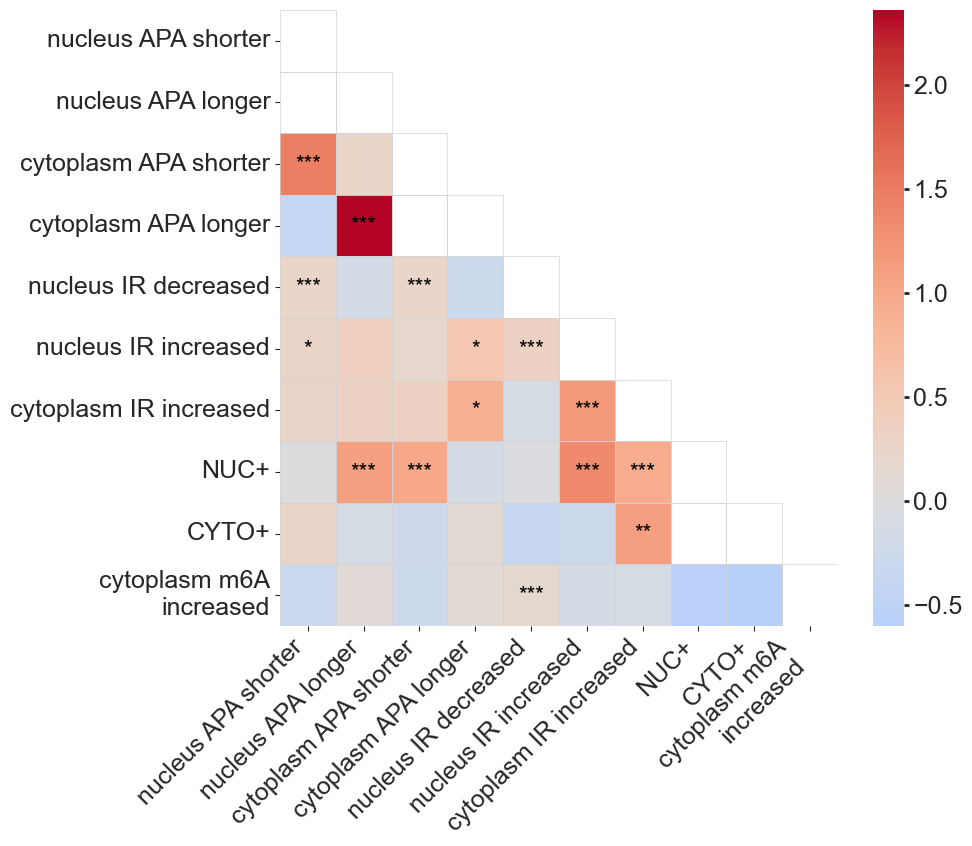

In [ ]:
# heatmap plot

mask = np.triu(np.ones_like(hypergeom_df_heatmap_piv, dtype=bool),k=1) # mask half the heatmap

plt.figure(figsize=(9,8))
ax = sns.heatmap(hypergeom_df_heatmap_piv,cmap='coolwarm', center = 0, mask = mask)

# add stars in heatmap cells
for i in range(hypergeom_df_heatmap_piv.shape[0]):
    for j in range(hypergeom_df_heatmap_piv.shape[1]):
        if not mask[i,j] : # false in mask matrix
            rect = patches.Rectangle((j, i), 1, 1,linewidth=0.5,edgecolor='lightgrey',facecolor='none')
            ax.add_patch(rect)
            p = hypergeom_df_pvalue_piv.iloc[i, j]
            if p < 0.001:
                stars = '***'
            elif p < 0.01:
                stars = '**'
            elif p < 0.05:
                stars = '*'
            else:
                stars = ''
            if stars:
                ax.text(j + 0.5, i + 0.5, stars, ha='center', va='center', color='black', fontsize=16)

plt.xticks(rotation = 45, ha='right')
plt.tick_params(labelsize=18)
ax.collections[0].colorbar.ax.tick_params(labelsize=18, width = 2)